**Задачи:**
1. Очистить тексты от шума и применить лемматизацию.
2. Построить мешок слов, сравнить с вариантом с N-граммами.
3. Построить TF-IDF-матрицу, выделить ключевые слова.
4. Провести разведочный анализ: частоты, длины, косинусное сходство.
5. Оформить выводы по каждому этапу.

## Задание 1. Очистка и лемматизация (2 балла)

Напишите функцию `clean_text`, которая приводит текст к нижнему регистру, удаляет ссылки, HTML-теги, хэштеги, цифры и всё, кроме русских букв и пробелов, схлопывает повторные пробелы.

Примените `clean_text` и лемматизацию (или стемминг) к столбцу `text`. Результат — в столбец `text_prepared`.

**Что требуется в отчёте:**
- 3–5 примеров «до / после очистки»;
- 5 примеров «до / после лемматизации»;
- число уникальных слов до и после обработки;
- обоснование, почему вы выбрали лемматизацию или стемминг.

In [18]:
import re
import pandas as pd
from nltk.stem.snowball import SnowballStemmer

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'#\w+', '', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^а-я\s]', '', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

stemmer = SnowballStemmer("russian")

def stem_text(text):
    words = text.split()
    stems = [stemmer.stem(word) for word in words]
    return ' '.join(stems)

df = pd.read_csv('reviews.csv')

df['text_cleaned'] = df['text'].apply(clean_text)
df['text_prepared'] = df['text_cleaned'].apply(stem_text)

print("3–5 примеров до и после очистки")
for i in range(5):
    print(f"Пример {i+1}:")
    print(f"  До:    {df['text'].iloc[i]}")
    print(f"  После: {df['text_cleaned'].iloc[i]}")
    print()

print("5 примеров до и после стемминга")
for i in range(5):
    print(f"Пример {i+1}:")
    print(f"  До:    {df['text_cleaned'].iloc[i]}")
    print(f"  После: {df['text_prepared'].iloc[i]}")
    print()

all_words_before = ' '.join(df['text'].astype(str)).lower().split()
all_words_after = ' '.join(df['text_prepared']).split()

print("Число уникальных слов до и после обработки")
print(f"До обработки: {len(set(all_words_before))}")
print(f"После стемминга: {len(set(all_words_after))}")

3–5 примеров до и после очистки
Пример 1:
  До:    Отличный фильм! Сюжет захватывает с первых минут, актёры играют прекрасно.
  После: отличный фильм сюжет захватывает с первых минут актры играют прекрасно

Пример 2:
  До:    Скучно и затянуто, еле досмотрел до конца. Больше не буду смотреть такого режиссёра.
  После: скучно и затянуто еле досмотрел до конца больше не буду смотреть такого режиссра

Пример 3:
  До:    Превосходная игра актёров! Особенно главный герой — просто находка для этого фильма.
  После: превосходная игра актров особенно главный герой просто находка для этого фильма

Пример 4:
  До:    УЖАСНЫЙ СЦЕНАРИЙ, ничего не понятно. Потратил 2 часа зря.
  После: ужасный сценарий ничего не понятно потратил часа зря

Пример 5:
  До:    Замечательная режиссура и красивые пейзажи. Смотрел на https://example.com/trailer — трейлер не обманул!
  После: замечательная режиссура и красивые пейзажи смотрел на трейлер не обманул

5 примеров до и после стемминга
Пример 1:
  До:    отличн

## Задание 2. Мешок слов и N-граммы (1,5 балла)

**2.1.** Постройте `CountVectorizer()` на `text_prepared`, выведите `.shape`.

**2.2.** Постройте `CountVectorizer(ngram_range=(1, 2))`, выведите `.shape`. Сравните размерность с 2.1.

**2.3.** Повторите оба варианта с фильтрами `min_freq=2, max_df=0.9`. Объясните, что произошло со словарём.

**Что требуется в отчёте:**
- таблица размерностей (вариант → число документов × число признаков);
- объяснение, почему при добавлении биграмм словарь вырос;
- что изменилось после фильтров.

In [22]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# 2.1
cv_uni = CountVectorizer()
X_uni = cv_uni.fit_transform(df['text_prepared'])
print("2.1. Униграммы (базовый CountVectorizer)")
print(f"Размерность матрицы: {X_uni.shape}")
print()

# 2.2
cv_bi = CountVectorizer(ngram_range=(1, 2))
X_bi = cv_bi.fit_transform(df['text_prepared'])
print("2.2. Униграммы и биграммы (ngram_range=(1, 2))")
print(f"Размерность матрицы: {X_bi.shape}")
print(f"Размерность увеличилась с {X_uni.shape[1]} до {X_bi.shape[1]} признаков.")
print()

# 2.3
cv_uni_f = CountVectorizer(min_df=2, max_df=0.9)
X_uni_f = cv_uni_f.fit_transform(df['text_prepared'])
print("2.3. Униграммы с фильтрами (min_df=2, max_df=0.9)")
print(f"Размерность матрицы: {X_uni_f.shape}")

cv_bi_f = CountVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9)
X_bi_f = cv_bi_f.fit_transform(df['text_prepared'])
print(f"Униграммы и биграммы с фильтрами: {X_bi_f.shape}")


2.1. Униграммы (базовый CountVectorizer)
Размерность матрицы: (25, 162)

2.2. Униграммы и биграммы (ngram_range=(1, 2))
Размерность матрицы: (25, 377)
Размерность увеличилась с 162 до 377 признаков.

2.3. Униграммы с фильтрами (min_df=2, max_df=0.9)
Размерность матрицы: (25, 43)
Униграммы и биграммы с фильтрами: (25, 46)


## Задание 3. TF-IDF (2 балла)

**3.1.** Постройте `TfidfVectorizer(ngram_range=(1, 2), max_feature=200)` на `text_prepared`.

**3.2.** Для каждого документа выведите топ-3 слова по TF-IDF-весу.

**3.3.** Постройте ту же матрицу с `stop_words='russian'`, чтобы убрать союзы и предлоги. Сравните топ-слова с 3.2.

**Что требуется в отчёте:**
- таблица топ-3 слов по каждому документу (для 3.2 и 3.3);
- какие слова попали в топ и почему (смысловые или служебные);
- объяснение, что изменилось после добавления `stop_words`.

**Подсказка:** «сырые» веса TF-IDF без нормализации (`norm=None`) иногда удобнее для чтения, потому что числа в матрице становятся крупнее. Попробуйте сравнить с дефолтным вариантом.

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)
russian_stopwords = stopwords.words('russian')

In [32]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords', quiet=True)
russian_stopwords = stopwords.words('russian')

tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=200)
X_tfidf = tfidf.fit_transform(df['text_prepared'])
features = tfidf.get_feature_names_out()

print(" 3.2 Топ-3 слова (без стоп-слов) ")
for i in range(len(df)):
    row = X_tfidf[i].toarray().flatten()
    top_idx = row.argsort()[-3:][::-1]
    top_words = [(features[j], round(row[j], 3)) for j in top_idx if row[j] > 0]
    print(f"Документ {i+1}: {top_words}")

print("\n" + "="*50 + "\n")

tfidf_stop = TfidfVectorizer(ngram_range=(1, 2), max_features=200, stop_words=russian_stopwords)
X_tfidf_stop = tfidf_stop.fit_transform(df['text_prepared'])
features_stop = tfidf_stop.get_feature_names_out()

print(" 3.3 Топ-3 слова (со стоп-словами)")
for i in range(len(df)):
    row = X_tfidf_stop[i].toarray().flatten()
    top_idx = row.argsort()[-3:][::-1]
    top_words = [(features_stop[j], round(row[j], 3)) for j in top_idx if row[j] > 0]
    print(f"Документ {i+1}: {top_words}")

 3.2 Топ-3 слова (без стоп-слов) 
Документ 1: [('захватыва', np.float64(0.31)), ('захватыва перв', np.float64(0.31)), ('игра прекрасн', np.float64(0.31))]
Документ 2: [('не буд', np.float64(0.249)), ('ел досмотрел', np.float64(0.249)), ('досмотрел до', np.float64(0.249))]
Документ 3: [('для эт', np.float64(0.283)), ('гер прост', np.float64(0.283)), ('гер', np.float64(0.283))]
Документ 4: [('час зря', np.float64(0.382)), ('нич', np.float64(0.382)), ('не понятн', np.float64(0.382))]
Документ 5: [('обманул', np.float64(0.317)), ('не обманул', np.float64(0.317)), ('красив пейзаж', np.float64(0.317))]
Документ 6: [('плох', np.float64(0.772)), ('не рекоменд', np.float64(0.386)), ('рекоменд', np.float64(0.342))]
Документ 7: [('обязательн', np.float64(0.297)), ('один из', np.float64(0.297)), ('обязательн смотр', np.float64(0.297))]
Документ 8: [('актрск', np.float64(0.442)), ('актрск состав', np.float64(0.442)), ('больш от', np.float64(0.442))]
Документ 9: [('раз', np.float64(0.557)), ('чтот н

## Задание 4. Разведочный анализ (2 балла)

**4.1. Частоты.** Топ-15 слов по частоте в `text_prepared`. Горизонтальная диаграмма.

**4.2. Длины.** Гистограмма длин документов (в словах). Минимум, максимум, среднее, медиана. Есть ли выбросы?

**4.3. Сходство.** Матрица косинусного сходства по TF-IDF-матрице из задания 3. Найдите:
- пару самых похожих документов (индексы и значение);
- пару самых непохожих;
- документ, который в среднем ближе всех к остальным.

**Что требуется в отчёте:**
- график топ-15 слов и вывод;
- график длин и вывод (есть ли документы-выбросы);
- три пары документов с числами и коротким объяснением, почему эти пары похожи / непохожи.

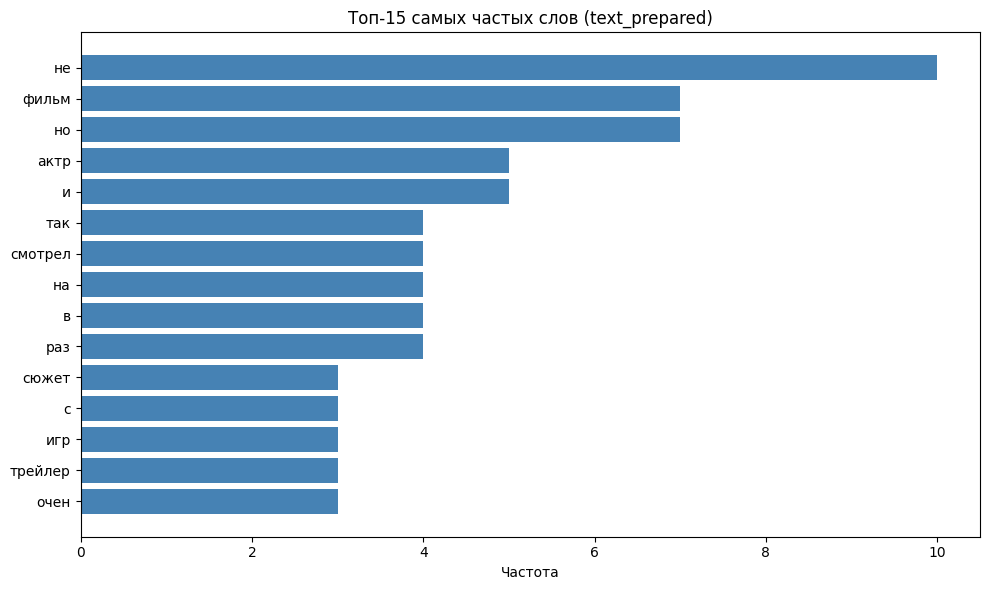


 4.2 Статистика длин 
Минимум:  5
Максимум: 14
Среднее:  10.4
Медиана:  10.0


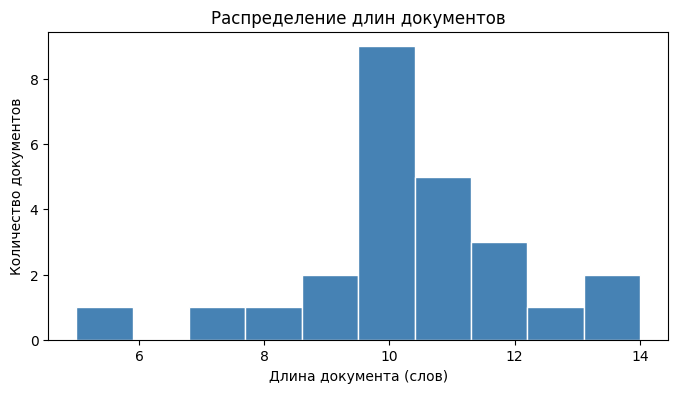


4.3 Анализ сходства
Самая похожая пара: Документ 1 и Документ 10 (Сходство: 0.378)
Самая непохожая пара: Документ 16 и Документ 3 (Сходство: 0.029)
Самый 'центральный' документ: Документ 1 (Среднее сходство: 0.036)


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.metrics.pairwise import cosine_similarity

all_words = ' '.join(df['text_prepared']).split()
word_counts = Counter(all_words)
top_15 = word_counts.most_common(15)

words_top = [w for w, _ in top_15]
counts_top = [c for _, c in top_15]

plt.figure(figsize=(10, 6))
plt.barh(words_top[::-1], counts_top[::-1], color='steelblue')
plt.xlabel('Частота')
plt.title('Топ-15 самых частых слов (text_prepared)')
plt.tight_layout()
plt.show()

lengths = [len(t.split()) for t in df['text_prepared']]

print(f"\n 4.2 Статистика длин ")
print(f"Минимум:  {min(lengths)}")
print(f"Максимум: {max(lengths)}")
print(f"Среднее:  {np.mean(lengths):.1f}")
print(f"Медиана:  {np.median(lengths):.1f}")

plt.figure(figsize=(8, 4))
plt.hist(lengths, bins=10, color='steelblue', edgecolor='white')
plt.xlabel('Длина документа (слов)')
plt.ylabel('Количество документов')
plt.title('Распределение длин документов')
plt.show()

similarity = cosine_similarity(X_tfidf_stop)

sim_copy = similarity.copy()
np.fill_diagonal(sim_copy, 0)

max_idx = np.unravel_index(np.argmax(sim_copy), sim_copy.shape)
doc1_max, doc2_max = max_idx[0], max_idx[1]
max_val = sim_copy[max_idx]

sim_lower = np.tril(similarity, -1)
sim_lower[sim_lower == 0] = 1
min_idx = np.unravel_index(np.argmin(sim_lower), sim_lower.shape)
doc1_min, doc2_min = min_idx[0], min_idx[1]
min_val = sim_lower[min_idx]

avg_similarities = (similarity.sum(axis=1) - 1) / (len(df) - 1)
center_doc_idx = np.argmax(avg_similarities)

print(f"\n4.3 Анализ сходства")
print(f"Самая похожая пара: Документ {doc1_max+1} и Документ {doc2_max+1} (Сходство: {max_val:.3f})")
print(f"Самая непохожая пара: Документ {doc1_min+1} и Документ {doc2_min+1} (Сходство: {min_val:.3f})")
print(f"Самый 'центральный' документ: Документ {center_doc_idx+1} (Среднее сходство: {avg_similarities[center_doc_idx]:.3f})")